**##Predicting Load_Type of a Power System**

**Goal:** classify each 15-minute reading as `Light_Load`, `Medium_Load` or `Maximum_Load`.

**Plan**
1. Load and clean the data
2. EDA
3. Feature engineering (using only past data, no leakage)
4. Split: Jan–Oct = train, Nov = validation, Dec = test (last month, as required)
5. Compare models on the validation month
6. Retrain the best model on Jan–Nov and evaluate once on December

# 1. Load data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings("ignore")

In [2]:
df=pd.read_csv("load_data.csv")
df.head()

,Date_Time,Usage_kWh,Lagging_Current_Reactive.Power_kVarh,Leading_Current_Reactive_Power_kVarh,CO2(tCO2),Lagging_Current_Power_Factor,Leading_Current_Power_Factor,NSM,Load_Type
0,01-01-2018 00:15,8.753692,2.95,0.0,0.0,73.210000,100.0,900.000000,Light_Load
1,01-01-2018 00:30,4.000000,4.46,0.0,0.0,66.770000,100.0,1800.000000,Light_Load
2,01-01-2018 00:45,3.240000,3.28,0.0,0.0,70.280000,100.0,8070.880991,Light_Load
3,01-01-2018 01:00,3.310000,3.56,0.0,0.0,68.090000,100.0,3600.000000,Light_Load
4,01-01-2018 01:15,3.820000,4.50,0.0,0.0,133.655666,NaN,4500.000000,Light_Load


In [3]:
df["Date_Time"]=pd.to_datetime(df["Date_Time"],format="%d-%m-%Y %H:%M")

In [4]:
print(df.shape)

(35041, 9)


In [5]:
df.info() 

<class 'pandas.DataFrame'>
RangeIndex: 35041 entries, 0 to 35040
Data columns (total 9 columns):
 #   Column                                Non-Null Count  Dtype         
---  ------                                --------------  -----         
 0   Date_Time                             35041 non-null  datetime64[us]
 1   Usage_kWh                             33482 non-null  float64       
 2   Lagging_Current_Reactive.Power_kVarh  34165 non-null  float64       
 3   Leading_Current_Reactive_Power_kVarh  33885 non-null  float64       
 4   CO2(tCO2)                             34586 non-null  float64       
 5   Lagging_Current_Power_Factor          34691 non-null  float64       
 6   Leading_Current_Power_Factor          33570 non-null  float64       
 7   NSM                                   34586 non-null  float64       
 8   Load_Type                             35041 non-null  str           
dtypes: datetime64[us](1), float64(7), str(1)
memory usage: 2.4 MB


## 2. Missing values and target distribution

In [6]:
print(df.isnull().sum())

Date_Time                                  0
Usage_kWh                               1559
Lagging_Current_Reactive.Power_kVarh     876
Leading_Current_Reactive_Power_kVarh    1156
CO2(tCO2)                                455
Lagging_Current_Power_Factor             350
Leading_Current_Power_Factor            1471
NSM                                      455
Load_Type                                  0
dtype: int64


In [7]:
print(df["Load_Type"].value_counts())
print(df["Load_Type"].value_counts(normalize=True) * 100)

Load_Type
Light_Load      18073
Medium_Load      9696
Maximum_Load     7272
Name: count, dtype: int64
Load_Type
Light_Load      51.576724
Medium_Load     27.670443
Maximum_Load    20.752832
Name: proportion, dtype: float64


In [8]:
df.describe().T

,count,mean,min,25%,50%,75%,max,std
Date_Time,35041,2018-07-02 11:59:59.589052,2018-01-01 00:00:00,2018-04-02 06:00:00,2018-07-02 12:00:00,2018-10-01 18:00:00,2018-12-31 23:45:00,NaN
Usage_kWh,33482.0,30.873061,0.0,3.31,5.29,53.56,435.019069,41.415015
Lagging_Current_Reactive.Power_kVarh,34165.0,14.704573,0.0,2.34,5.18,23.51,262.630718,20.342721
Leading_Current_Reactive_Power_kVarh,33885.0,4.386097,0.0,0.0,0.0,2.298558,78.809,9.090181
CO2(tCO2),34586.0,0.012947,0.0,0.0,0.0,0.02,0.188166,0.019726
Lagging_Current_Power_Factor,34691.0,90.740871,0.0,66.295,90.08,100.0,299.996814,39.745395
Leading_Current_Power_Factor,33570.0,94.926552,0.0,99.8,100.0,100.0,299.969494,49.826872
NSM,34586.0,48013.664032,0.0,22500.0,45000.0,68400.0,248821.810465,34046.492333


## 3. EDA

In [9]:
df["hour"] = df["Date_Time"].dt.hour
df["dayofweek"] = df["Date_Time"].dt.dayofweek 
df["month"] = df["Date_Time"].dt.month

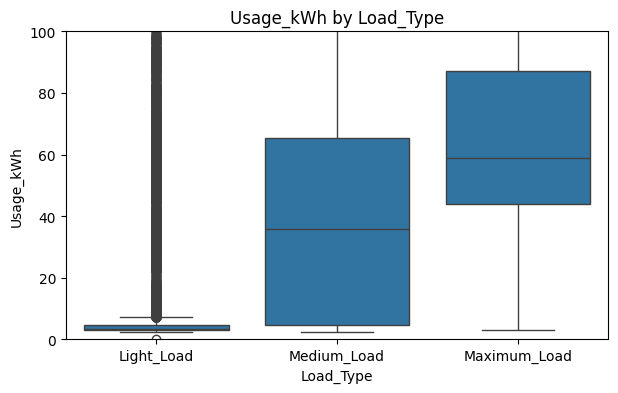

In [10]:
plt.figure(figsize=(7,4))
sns.boxplot(data=df, x="Load_Type", y="Usage_kWh",order=["Light_Load","Medium_Load","Maximum_Load"])
plt.ylim(0, 100)  
plt.title("Usage_kWh by Load_Type")
plt.show()

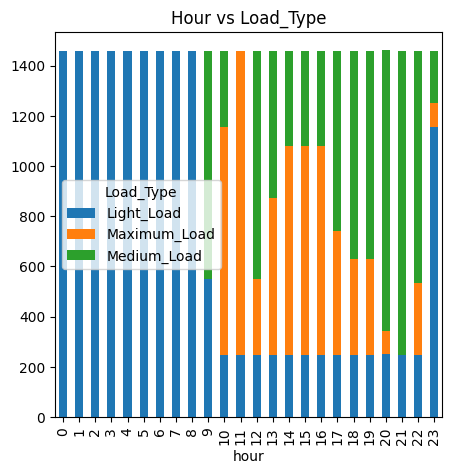

In [11]:
pd.crosstab(df["hour"], df["Load_Type"]).plot(kind="bar", stacked=True, figsize=(5,5))
plt.title("Hour vs Load_Type")
plt.show()

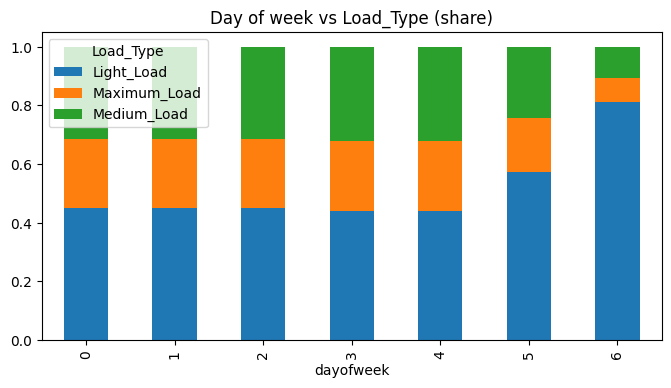

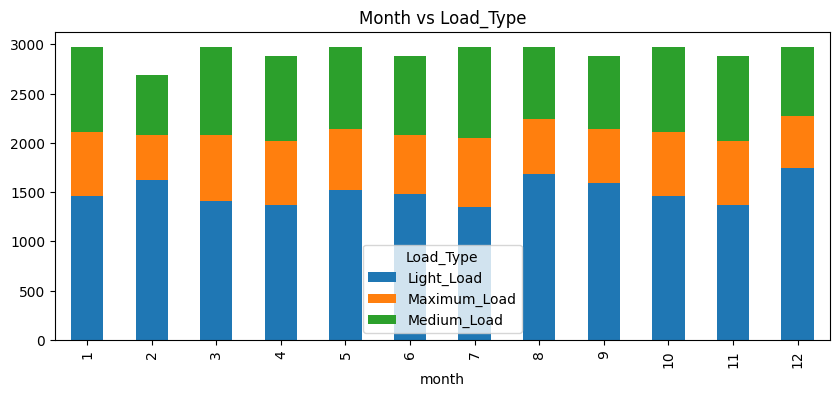

In [12]:
pd.crosstab(df["dayofweek"], df["Load_Type"], normalize="index").plot(kind="bar", stacked=True, figsize=(8,4))
plt.title("Day of week vs Load_Type (share)")
plt.show()

pd.crosstab(df["month"], df["Load_Type"]).plot(kind="bar", stacked=True, figsize=(10,4))
plt.title("Month vs Load_Type")
plt.show()

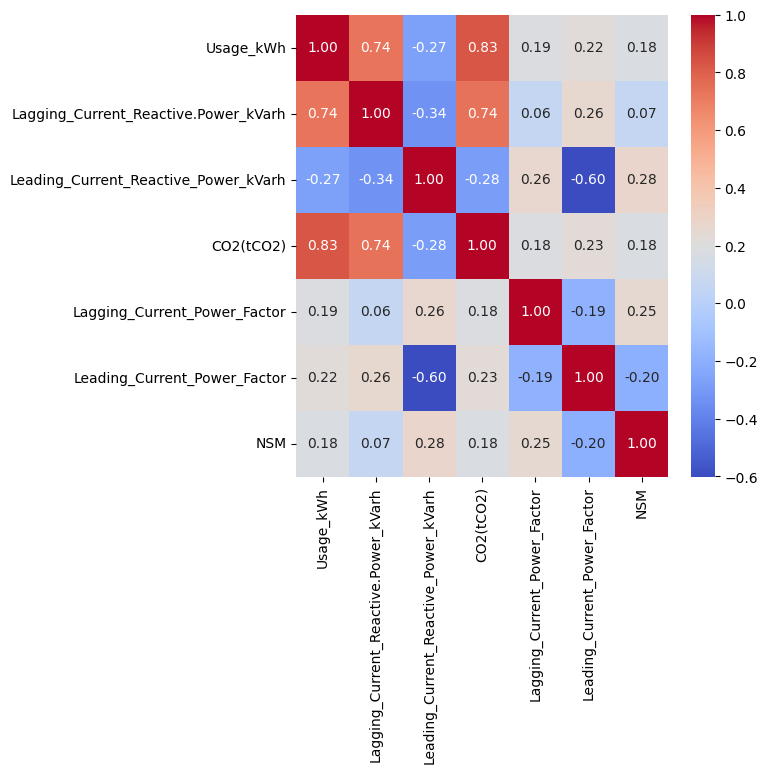

In [13]:
num_cols = df.select_dtypes("number").drop(columns=["hour","dayofweek","month"])
plt.figure(figsize=(6,6))
sns.heatmap(num_cols.corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.show()

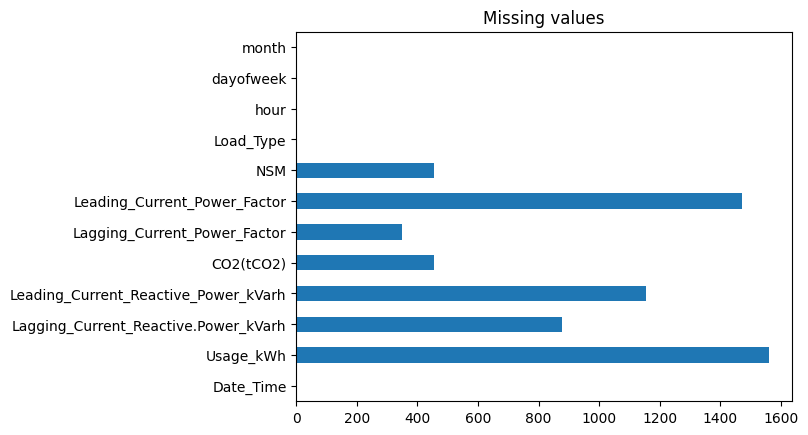

,Lagging_Current_Power_Factor,Leading_Current_Power_Factor,NSM
count,34691.000000,33570.000000,34586.000000
mean,90.740871,94.926552,48013.664032
std,39.745395,49.826872,34046.492333
min,0.000000,0.000000,0.000000
25%,66.295000,99.800000,22500.000000
50%,90.080000,100.000000,45000.000000
75%,100.000000,100.000000,68400.000000
max,299.996814,299.969494,248821.810465


In [14]:
df.isnull().sum().plot(kind="barh", title="Missing values")
plt.show()

df[["Lagging_Current_Power_Factor","Leading_Current_Power_Factor","NSM"]].describe()

## 4. Data cleaning

**NSM fix:** NSM (seconds from midnight) must lie between 0 and 86,400, but the raw column has values up to ~248,000 and some missing values.
Since NSM can be computed exactly from `Date_Time`, it is rebuilt from the timestamp.

In [15]:
df["NSM"] = df["Date_Time"].dt.hour * 3600 + df["Date_Time"].dt.minute * 60
print(df["NSM"].describe())   # max 85500 ke aaspaas aana chahiye

count    35041.000000
mean     42750.834736
std      24940.667915
min          0.000000
25%      21600.000000
50%      43200.000000
75%      64800.000000
max      85500.000000
Name: NSM, dtype: float64


**Power factor fix:** a power factor is a percentage, so it cannot be above 100.
Values above 100 are invalid readings and are set to NaN (filled later with the train median).

In [16]:
pf_cols = ["Lagging_Current_Power_Factor", "Leading_Current_Power_Factor"]
for c in pf_cols:
    print(c, "galat rows:", (df[c] > 100).sum())
    df.loc[df[c] > 100, c] = np.nan

Lagging_Current_Power_Factor galat rows: 3226
Leading_Current_Power_Factor galat rows: 2685


## 5. Leakage-free features

A daily mean/max of `Usage_kWh` would use readings from **later in the same day**. At 10:00 AM we cannot know how much power the rest of the day will use, so that would be look-ahead leakage.

Instead, every usage-based feature below uses only **past** readings (`shift(1)` excludes the current row):
- `usage_lag1` — previous reading
- `roll_mean_4` — mean of the last 1 hour (4 readings)
- `roll_mean_96` — mean of the last 24 hours (96 readings)
- `day_so_far_mean` — mean of today's readings before this one
- `prev_day_mean` — mean usage of the previous day

In [17]:
df = df.sort_values("Date_Time").reset_index(drop=True)
df["date"] = df["Date_Time"].dt.date

u = df["Usage_kWh"]
df["usage_lag1"]      = u.shift(1)
df["roll_mean_4"]     = u.shift(1).rolling(4, min_periods=1).mean()     # last 1 hour
df["roll_mean_96"]    = u.shift(1).rolling(96, min_periods=1).mean()    # last 24 hours
df["day_so_far_mean"] = df.groupby("date")["Usage_kWh"].transform(lambda s: s.shift(1).expanding().mean())
df["prev_day_mean"]   = df["date"].map(df.groupby("date")["Usage_kWh"].mean().shift(1))

df[["Date_Time", "Usage_kWh", "usage_lag1", "roll_mean_4", "day_so_far_mean", "prev_day_mean"]].head()

,Date_Time,Usage_kWh,usage_lag1,roll_mean_4,day_so_far_mean,prev_day_mean
0,2018-01-01 00:00:00,3.420000,NaN,NaN,NaN,NaN
1,2018-01-01 00:15:00,8.753692,3.420000,3.420000,3.420000,NaN
2,2018-01-01 00:30:00,4.000000,8.753692,6.086846,6.086846,NaN
3,2018-01-01 00:45:00,3.240000,4.000000,5.391231,5.391231,NaN
4,2018-01-01 01:00:00,3.310000,3.240000,4.853423,4.853423,NaN


## 6. Train / validation / test split (time-based)

- **Train:** Jan–Oct 2018
- **Validation:** Nov 2018 — used to compare and choose models
- **Test:** Dec 2018 — the last month, used **only once** at the end

In [18]:
train = df[df["Date_Time"] < "2018-11-01"].copy()
valid = df[(df["Date_Time"] >= "2018-11-01") & (df["Date_Time"] < "2018-12-01")].copy()
test  = df[df["Date_Time"] >= "2018-12-01"].copy()
print("train:", train.shape, " valid:", valid.shape, " test:", test.shape)

train: (29184, 18)  valid: (2880, 18)  test: (2977, 18)


Missing values are filled with medians computed **from train only**, then applied to validation and test.

In [19]:
num_cols = ["Usage_kWh", "Lagging_Current_Reactive.Power_kVarh",
            "Leading_Current_Reactive_Power_kVarh", "CO2(tCO2)",
            "Lagging_Current_Power_Factor", "Leading_Current_Power_Factor",
            "usage_lag1", "roll_mean_4", "roll_mean_96", "day_so_far_mean", "prev_day_mean"]

medians = train[num_cols].median()     # sirf train se
for d in (train, valid, test):
    d[num_cols] = d[num_cols].fillna(medians)

print(train[num_cols].isnull().sum().sum(), valid[num_cols].isnull().sum().sum(), test[num_cols].isnull().sum().sum())   # teeno 0 aane chahiye

0 0 0


## 7. Time and power features

`time_sin` / `time_cos` encode time of day as a circle, so 23:45 and 00:00 end up close together (helps linear models).

In [20]:
def add_features(d):
    d = d.copy()
    d["hour"] = d["Date_Time"].dt.hour
    d["minute"] = d["Date_Time"].dt.minute
    d["dayofweek"] = d["Date_Time"].dt.dayofweek
    d["is_weekend"] = (d["dayofweek"] >= 5).astype(int)
    d["is_sunday"] = (d["dayofweek"] == 6).astype(int)
    d["is_winter"] = d["Date_Time"].dt.month.isin([11, 12, 1, 2]).astype(int)
    d["time_sin"] = np.sin(2 * np.pi * d["NSM"] / 86400)
    d["time_cos"] = np.cos(2 * np.pi * d["NSM"] / 86400)
    return d

def add_power_features(d):
    d = d.copy()
    d["total_reactive"] = d["Lagging_Current_Reactive.Power_kVarh"] + d["Leading_Current_Reactive_Power_kVarh"]
    d["usage_per_co2"] = d["Usage_kWh"] / (d["CO2(tCO2)"] + 1e-6)
    return d

train, valid, test = [add_power_features(add_features(d)) for d in (train, valid, test)]

In [21]:
drop_cols = ["Date_Time", "Load_Type", "date", "month"]
feature_cols = [c for c in train.columns if c not in drop_cols]
print(len(feature_cols), "features:")
print(feature_cols)

22

 features:
['Usage_kWh', 'Lagging_Current_Reactive.Power_kVarh', 'Leading_Current_Reactive_Power_kVarh', 'CO2(tCO2)', 'Lagging_Current_Power_Factor', 'Leading_Current_Power_Factor', 'NSM', 'hour', 'dayofweek', 'usage_lag1', 'roll_mean_4', 'roll_mean_96', 'day_so_far_mean', 'prev_day_mean', 'minute', 'is_weekend', 'is_sunday', 'is_winter', 'time_sin', 'time_cos', 'total_reactive', 'usage_per_co2']


In [22]:
label_map = {"Light_Load": 0, "Medium_Load": 1, "Maximum_Load": 2}
target_names = ["Light_Load", "Medium_Load", "Maximum_Load"]

X_train, y_train = train[feature_cols], train["Load_Type"].map(label_map)
X_valid, y_valid = valid[feature_cols], valid["Load_Type"].map(label_map)
X_test,  y_test  = test[feature_cols],  test["Load_Type"].map(label_map)

print(X_train.shape, X_valid.shape, X_test.shape)
print(y_train.value_counts())

(29184, 22) (2880, 22) (2977, 22)
Load_Type
0    14960
1     8128
2     6096
Name: count, dtype: int64


## 8. Models

In [23]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix
from lightgbm import LGBMClassifier
from xgboost import XGBClassifier

The tree models are lightly regularised (limited depth, minimum samples per leaf, row/column subsampling) so they learn general patterns instead of memorising the training rows.
Class weights handle the imbalance (Light_Load is ~52% of the data).

In [24]:
models = {
    "Logistic Regression": make_pipeline(StandardScaler(),
                                         LogisticRegression(max_iter=1000, class_weight="balanced")),
    "Random Forest": RandomForestClassifier(n_estimators=300, max_depth=15, min_samples_leaf=5,
                                            class_weight="balanced", random_state=42, n_jobs=-1),
    "LightGBM": LGBMClassifier(n_estimators=500, learning_rate=0.05, min_child_samples=50,
                               subsample=0.8, subsample_freq=1, colsample_bytree=0.8,
                               reg_lambda=1.0, class_weight="balanced", random_state=42, verbose=-1),
    "XGBoost": XGBClassifier(n_estimators=500, learning_rate=0.05, max_depth=6, min_child_weight=5,
                             subsample=0.8, colsample_bytree=0.8, random_state=42, eval_metric="mlogloss"),
}

def fit_model(name, model, X, y):
    if name == "XGBoost":   # XGBoost has no class_weight, so use sample weights
        model.fit(X, y, sample_weight=compute_sample_weight("balanced", y))
    else:
        model.fit(X, y)
    return model

## 9. Model selection on the validation month (November)

Train F1 and validation F1 are shown side by side. A small gap between them means the model is **not overfitting**.

In [25]:
results = []
for name, model in models.items():
    fit_model(name, model, X_train, y_train)
    p_val = model.predict(X_valid)
    results.append({
        "Model": name,
        "Train F1": f1_score(y_train, model.predict(X_train), average="macro"),
        "Valid Accuracy": accuracy_score(y_valid, p_val),
        "Valid F1": f1_score(y_valid, p_val, average="macro"),
    })

res = pd.DataFrame(results).sort_values("Valid F1", ascending=False).reset_index(drop=True)
res["Gap (Train - Valid)"] = res["Train F1"] - res["Valid F1"]
best = res.loc[0, "Model"]
print("Best model on validation:", best)
res

Best model on validation: XGBoost


,Model,Train F1,Valid Accuracy,Valid F1,Gap (Train - Valid)
0,XGBoost,1.000000,0.999653,0.999621,0.000379
1,LightGBM,1.000000,0.997222,0.996463,0.003537
2,Random Forest,0.999626,0.977431,0.970970,0.028656
3,Logistic Regression,0.852819,0.663194,0.570388,0.282431


## 10. Extra check: walk-forward validation

To confirm the model works across the year and not just in one month, the best model is trained on all months before month *m* and tested on month *m* (June to November).

In [26]:
from sklearn.base import clone

trval = pd.concat([train, valid])
months = trval["Date_Time"].dt.month
wf = []
for m in range(6, 12):
    tr, te = months < m, months == m
    mdl = fit_model(best, clone(models[best]), trval.loc[tr, feature_cols], trval.loc[tr, "Load_Type"].map(label_map))
    p = mdl.predict(trval.loc[te, feature_cols])
    wf.append({"Test month": m, "Macro F1": f1_score(trval.loc[te, "Load_Type"].map(label_map), p, average="macro")})

wf = pd.DataFrame(wf)
print("Mean walk-forward Macro F1:", round(wf["Macro F1"].mean(), 4))
wf

Mean walk-forward Macro F1: 0.9957


,Test month,Macro F1
0,6,0.998256
1,7,1.000000
2,8,0.979746
3,9,0.999262
4,10,0.997535
5,11,0.999621


## 11. Final evaluation on the test month (December)

The best model is retrained on Jan–Nov and evaluated **once** on December.

In [27]:
X_full = pd.concat([X_train, X_valid])
y_full = pd.concat([y_train, y_valid])

final_model = fit_model(best, clone(models[best]), X_full, y_full)
p_test = final_model.predict(X_test)

print(f"Model: {best}")
print("Test Accuracy:", round(accuracy_score(y_test, p_test), 4))
print("Test Macro F1:", round(f1_score(y_test, p_test, average="macro"), 4))
print()
print(classification_report(y_test, p_test, target_names=target_names, digits=3))

Model: XGBoost
Test Accuracy: 0.9896
Test Macro F1: 0.9884

              precision    recall  f1-score   support

  Light_Load      0.983     0.999     0.991      1745
 Medium_Load      0.999     0.980     0.989       704
Maximum_Load      1.000     0.970     0.985       528

    accuracy                          0.990      2977
   macro avg      0.994     0.983     0.988      2977
weighted avg      0.990     0.990     0.990      2977



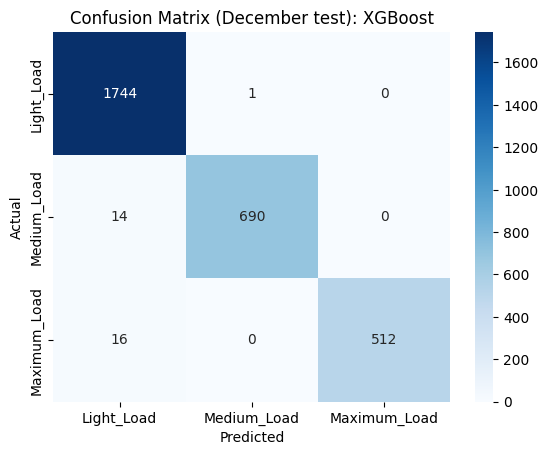

In [28]:
cm = confusion_matrix(y_test, p_test)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=target_names, yticklabels=target_names)
plt.xlabel("Predicted"); plt.ylabel("Actual")
plt.title(f"Confusion Matrix (December test): {best}")
plt.show()

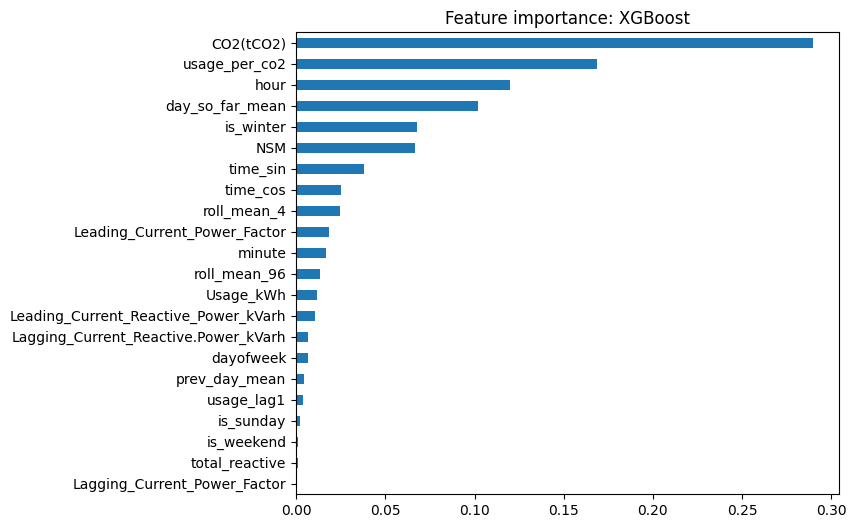

In [29]:
imp = pd.Series(final_model.feature_importances_, index=feature_cols).sort_values()
imp.plot(kind="barh", figsize=(7, 6), title=f"Feature importance: {best}")
plt.show()

## 12. Conclusion

- **Why are the scores so high?** `Load_Type` mostly follows a fixed time-of-day schedule. For example, every reading from midnight to 09:00 is `Light_Load`, and Sundays are almost all `Light_Load`. The rest is decided by whether the plant is running, which the usage features capture.
- **Leakage avoided:** all usage-based features use only past readings, and missing values are filled with train-only medians.
- **Fair evaluation:** models were compared on November (validation). December (test) was used only once, for the final score.
- **Not overfitting:** the gap between train and validation F1 is small, and walk-forward validation gives stable scores across every month.